<a href="https://colab.research.google.com/github/sxryadipta/tesla-study/blob/notebook/Tesla_Innovation_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Technology Innovations and Competitive Advantage: A Study of Tesla (2019–2025)
**Design:** secondary-data comparative case study (Tesla = focal case; BYD, Toyota = comparators). No surveys, no regression.


**Data-status labels used throughout**
- `reported` – figure printed in an official filing/release · `calculated` – derived here by formula · `judgement` – qualitative analyst rating
- Verification: `P` = checked against primary filing text · `S` = matched in secondary extraction only (confirm against primary) · `U` = unverified, **excluded from quantitative analysis**

**RQ map:** RQ1 §3–4 · RQ2 §9 · RQ3 §7–8 · RQ4 §5–6 · RQ5 §10

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, os, zipfile, json
from scipy import stats
os.makedirs('/content/outputs', exist_ok=True); OUT='/content/outputs/'
pd.set_option('display.width',200); pd.set_option('display.max_colwidth',90)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})

## 1. Tesla dataset (USD millions, FY = calendar year, US GAAP)
Values are *reported*. Ratios are computed in §3, never typed in.

In [ ]:
EDGAR_LIST='https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=0001318605&type=10-K&dateb=&owner=include&count=40'
FY25='https://www.sec.gov/Archives/edgar/data/1318605/000162828026003952/tsla-20251231.htm'
tesla = pd.DataFrame({
 'fiscal_year':[2019,2020,2021,2022,2023,2024,2025],
 'revenue':[24578,31536,53823,81462,96773,97690,94827],
 'rd_expense':[1343,1491,2593,3075,3969,4540,6411],
 'gross_profit':[4069,6630,13606,20853,17660,17450,17094],
 'reg_credits':[594,1580,1465,1776,1790,2763,1993],
})
tesla['source_url']=[EDGAR_LIST]*6+[FY25]
tesla['source_section']='Form 10-K, Item 8 Consolidated Statements of Operations; credits: Item 7 revenue table (Automotive regulatory credits)'
tesla['verification']=['S','S','S','S','S','S','P']
tesla['note']=['Not re-checked against filing text in this session; run §2 check','Not re-checked against filing text; run §2 check',
 'Matches edgar.tools + sec-api.io extractions','Matches edgar.tools + sec-api.io extractions','Matches edgar.tools + sec-api.io extractions',
 'Matches edgar.tools + sec-api.io extractions','Revenue & credits seen in SEC 10-K text (filed 2026-01-29); GP/R&D match two extractions']
tesla.to_csv(OUT+'tesla_reported_data.csv',index=False); tesla

,fiscal_year,revenue,rd_expense,gross_profit,reg_credits,source_url,source_section,verification,note
0,2019,24578,1343,4069,594,https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=0001318605&type=10-K&da...,"Form 10-K, Item 8 Consolidated Statements of Operations; credits: Item 7 revenue table...",S,Not re-checked against filing text in this session; run §2 check
1,2020,31536,1491,6630,1580,https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=0001318605&type=10-K&da...,"Form 10-K, Item 8 Consolidated Statements of Operations; credits: Item 7 revenue table...",S,Not re-checked against filing text; run §2 check
2,2021,53823,2593,13606,1465,https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=0001318605&type=10-K&da...,"Form 10-K, Item 8 Consolidated Statements of Operations; credits: Item 7 revenue table...",S,Matches edgar.tools + sec-api.io extractions
3,2022,81462,3075,20853,1776,https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=0001318605&type=10-K&da...,"Form 10-K, Item 8 Consolidated Statements of Operations; credits: Item 7 revenue table...",S,Matches edgar.tools + sec-api.io extractions
4,2023,96773,3969,17660,1790,https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=0001318605&type=10-K&da...,"Form 10-K, Item 8 Consolidated Statements of Operations; credits: Item 7 revenue table...",S,Matches edgar.tools + sec-api.io extractions
5,2024,97690,4540,17450,2763,https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=0001318605&type=10-K&da...,"Form 10-K, Item 8 Consolidated Statements of Operations; credits: Item 7 revenue table...",S,Matches edgar.tools + sec-api.io extractions
6,2025,94827,6411,17094,1993,https://www.sec.gov/Archives/edgar/data/1318605/000162828026003952/tsla-20251231.htm,"Form 10-K, Item 8 Consolidated Statements of Operations; credits: Item 7 revenue table...",P,Revenue & credits seen in SEC 10-K text (filed 2026-01-29); GP/R&D match two extractions


In [ ]:
import requests
USER_AGENT='Student Research suryadiptaghoshbt23ecevlsi@pec.edu.in'
def sec_annual(facts, tag):
    rows=[]
    for u in facts.get(tag,{}).get('units',{}).get('USD',[]):
        if u.get('form','').startswith('10-K') and 'start' in u:
            d=(pd.to_datetime(u['end'])-pd.to_datetime(u['start'])).days
            if 360<=d<=370: rows.append((int(u['end'][:4]),u['val']/1e6))
    return pd.DataFrame(rows,columns=['fiscal_year','val']).drop_duplicates()
xbrl_check=None
try:
    r=requests.get('https://data.sec.gov/api/xbrl/companyfacts/CIK0001318605.json',headers={'User-Agent':USER_AGENT},timeout=30)
    r.raise_for_status(); f=r.json()['facts']['us-gaap']; res=[]
    for col,tag in [('revenue','Revenues'),('gross_profit','GrossProfit'),('rd_expense','ResearchAndDevelopmentExpense')]:
        a=sec_annual(f,tag)
        for _,row in tesla.iterrows():
            vals=a[a.fiscal_year==row.fiscal_year].val.tolist()
            res.append((row.fiscal_year,col,row[col],vals,any(abs(v-row[col])<0.5 for v in vals)))
    xbrl_check=pd.DataFrame(res,columns=['fiscal_year','metric','dataset_value','sec_xbrl_values','match'])
    print('All match:',xbrl_check.match.all()); display(xbrl_check[~xbrl_check.match])
    if xbrl_check.match.all(): tesla['verification']='P'
except Exception as e:
    print('XBRL check not run:',e)

All match: True


,fiscal_year,metric,dataset_value,sec_xbrl_values,match


## 3. Calculated metrics (*calculated*)
- Gross margin % = Gross profit / Revenue × 100 · R&D intensity % = R&D / Revenue × 100
- **Credit-adjusted sensitivity** = (Gross profit − credits) / (Revenue − credits) × 100. Credits carry negligible cost (Tesla 10-K), so they are removed from numerator *and* denominator. This is a **consolidated-level sensitivity, not an official automotive gross margin**.

In [ ]:
d=tesla.copy()
d['gross_margin_pct']=d.gross_profit/d.revenue*100
d['rd_intensity_pct']=d.rd_expense/d.revenue*100
d['credits_pct_revenue']=d.reg_credits/d.revenue*100
d['credits_pct_gross_profit']=d.reg_credits/d.gross_profit*100
d['gm_ex_credits_sensitivity_pct']=(d.gross_profit-d.reg_credits)/(d.revenue-d.reg_credits)*100
d['gm_uplift_from_credits_pp']=d.gross_margin_pct-d.gm_ex_credits_sensitivity_pct
for c in ['revenue','rd_expense','gross_profit']: d[c+'_yoy_pct']=d[c].pct_change()*100
d['revenue_cagr_2019_25_pct']=((d.revenue.iloc[-1]/d.revenue.iloc[0])**(1/6)-1)*100
d['rd_cagr_2019_25_pct']=((d.rd_expense.iloc[-1]/d.rd_expense.iloc[0])**(1/6)-1)*100
cols=['fiscal_year','revenue','rd_expense','gross_profit','gross_margin_pct','rd_intensity_pct','gm_ex_credits_sensitivity_pct','credits_pct_gross_profit']
d.to_csv(OUT+'tesla_metrics.csv',index=False)
display(d[cols].round(2)); display(d[['fiscal_year','revenue_yoy_pct','rd_expense_yoy_pct','gross_profit_yoy_pct']].round(1))
print(f"Revenue CAGR 2019-25: {d.revenue_cagr_2019_25_pct[0]:.1f}% | R&D CAGR: {d.rd_cagr_2019_25_pct[0]:.1f}%")

,fiscal_year,revenue,rd_expense,gross_profit,gross_margin_pct,rd_intensity_pct,gm_ex_credits_sensitivity_pct,credits_pct_gross_profit
0,2019,24578,1343,4069,16.56,5.46,14.49,14.60
1,2020,31536,1491,6630,21.02,4.73,16.86,23.83
2,2021,53823,2593,13606,25.28,4.82,23.19,10.77
3,2022,81462,3075,20853,25.60,3.77,23.94,8.52
4,2023,96773,3969,17660,18.25,4.10,16.71,10.14
5,2024,97690,4540,17450,17.86,4.65,15.47,15.83
6,2025,94827,6411,17094,18.03,6.76,16.27,11.66


,fiscal_year,revenue_yoy_pct,rd_expense_yoy_pct,gross_profit_yoy_pct
0,2019,NaN,NaN,NaN
1,2020,28.3,11.0,62.9
2,2021,70.7,73.9,105.2
3,2022,51.4,18.6,53.3
4,2023,18.8,29.1,-15.3
5,2024,0.9,14.4,-1.2
6,2025,-2.9,41.2,-2.0


Revenue CAGR 2019-25: 25.2% | R&D CAGR: 29.8%


## 4. Descriptive statistics and trend figures (RQ1)

,mean,std,min,50%,max
revenue,68669.86,31683.95,24578.00,81462.00,97690.00
rd_expense,3346.00,1793.58,1343.00,3075.00,6411.00
gross_margin_pct,20.37,3.71,16.56,18.25,25.60
rd_intensity_pct,4.90,0.98,3.77,4.73,6.76


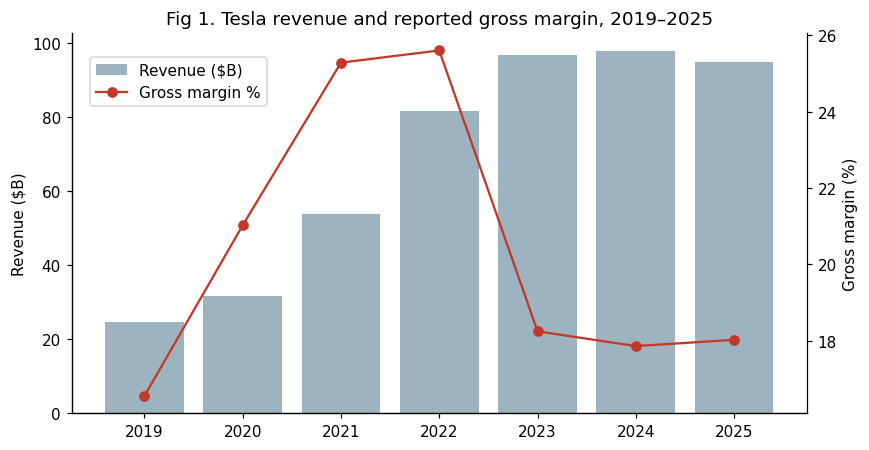

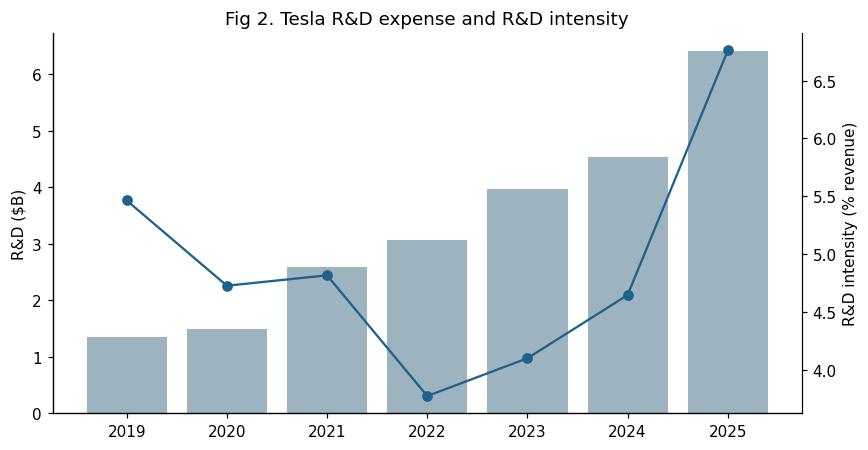

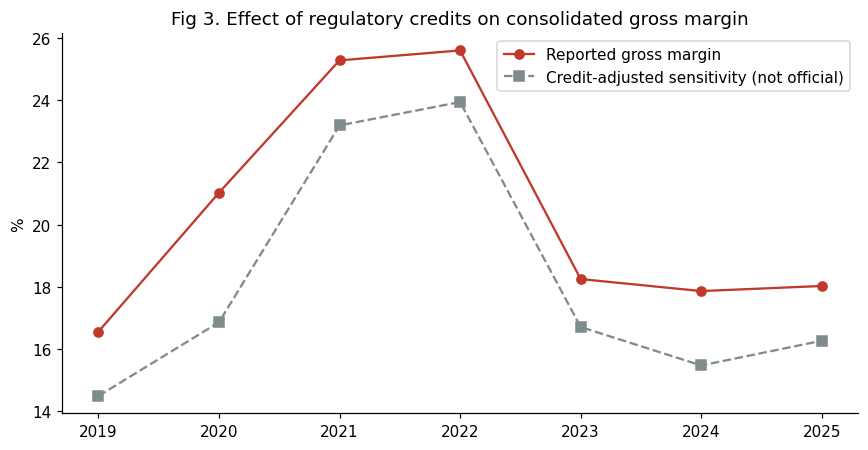

In [ ]:
desc=d[['revenue','rd_expense','gross_margin_pct','rd_intensity_pct']].describe().T[['mean','std','min','50%','max']].round(2)
desc.to_csv(OUT+'descriptive_stats.csv'); display(desc)
yrs=d.fiscal_year
fig,ax=plt.subplots(figsize=(8,4.2)); ax.bar(yrs,d.revenue/1000,color='#9db4c0',label='Revenue ($B)'); ax.set_ylabel('Revenue ($B)')
a2=ax.twinx(); a2.plot(yrs,d.gross_margin_pct,'o-',color='#c0392b',label='Gross margin %'); a2.set_ylabel('Gross margin (%)'); a2.spines['right'].set_visible(True)
ax.set_title('Fig 1. Tesla revenue and reported gross margin, 2019–2025'); fig.legend(loc='upper left',bbox_to_anchor=(.1,.88)); plt.tight_layout(); plt.savefig(OUT+'fig1_revenue_gm.png'); plt.show()
fig,ax=plt.subplots(figsize=(8,4.2)); ax.bar(yrs,d.rd_expense/1000,color='#9db4c0'); ax.set_ylabel('R&D ($B)')
a2=ax.twinx(); a2.plot(yrs,d.rd_intensity_pct,'o-',color='#1f618d'); a2.set_ylabel('R&D intensity (% revenue)'); a2.spines['right'].set_visible(True)
ax.set_title('Fig 2. Tesla R&D expense and R&D intensity'); plt.tight_layout(); plt.savefig(OUT+'fig2_rd.png'); plt.show()
fig,ax=plt.subplots(figsize=(8,4.2)); ax.plot(yrs,d.gross_margin_pct,'o-',label='Reported gross margin',color='#c0392b'); ax.plot(yrs,d.gm_ex_credits_sensitivity_pct,'s--',label='Credit-adjusted sensitivity (not official)',color='#7f8c8d')
ax.set_ylabel('%'); ax.set_title('Fig 3. Effect of regulatory credits on consolidated gross margin'); ax.legend(); plt.tight_layout(); plt.savefig(OUT+'fig3_credits.png'); plt.show()

## 5. Exploratory association: R&D intensity vs gross margin (RQ4)
n = 7. Pearson (linear) and Spearman (rank) are shown with Fisher-z 95% CIs, a leave-one-year-out check, and a one-year-lag variant. **Exploratory only: no causal claim, no regression, no significance-based conclusions.** Gross margin is also driven by price cuts, mix, tariffs/costs and credits; R&D (incl. AI spend) is expensed in the period and need not affect same-year margin.

In [ ]:
def corr_report(x,y,label):
    n=len(x); out={'pair':label,'n':n}
    for name,fn in [('pearson',stats.pearsonr),('spearman',stats.spearmanr)]:
        r,p=fn(x,y); out[name+'_r']=r; out[name+'_p']=p
        if n>3:
            z=np.arctanh(r); se=1/np.sqrt(n-3); lo,hi=np.tanh([z-1.96*se,z+1.96*se]); out[name+'_ci95']=f'[{lo:.2f}, {hi:.2f}]'
    return out
res=[corr_report(d.rd_intensity_pct,d.gross_margin_pct,'R&D intensity vs GM (same year)'),
     corr_report(d.rd_intensity_pct[:-1].values,d.gross_margin_pct[1:].values,'R&D intensity(t) vs GM(t+1)'),
     corr_report(d.rd_intensity_pct,d.gm_ex_credits_sensitivity_pct,'R&D intensity vs credit-adjusted GM'),
     corr_report(d.rd_intensity_pct.iloc[:-1],d.gross_margin_pct.iloc[:-1],'R&D intensity vs GM excl. 2025')]
corr=pd.DataFrame(res).round(3); corr.to_csv(OUT+'correlations.csv',index=False); display(corr)
loo=[(int(d.fiscal_year[i]),stats.pearsonr(d.rd_intensity_pct.drop(i),d.gross_margin_pct.drop(i))[0]) for i in range(len(d))]
loo=pd.DataFrame(loo,columns=['year_dropped','pearson_r']).round(3); loo.to_csv(OUT+'leave_one_out.csv',index=False); display(loo)

,pair,n,pearson_r,pearson_p,pearson_ci95,spearman_r,spearman_p,spearman_ci95
0,R&D intensity vs GM (same year),7,-0.484,0.271,"[-0.91, 0.42]",-0.500,0.253,"[-0.91, 0.41]"
1,R&D intensity(t) vs GM(t+1),6,0.492,0.322,"[-0.53, 0.93]",0.657,0.156,"[-0.33, 0.96]"
2,R&D intensity vs credit-adjusted GM,7,-0.466,0.291,"[-0.90, 0.44]",-0.500,0.253,"[-0.91, 0.41]"
3,R&D intensity vs GM excl. 2025,6,-0.477,0.339,"[-0.93, 0.55]",-0.486,0.329,"[-0.93, 0.54]"


,year_dropped,pearson_r
0,2019,-0.428
1,2020,-0.481
2,2021,-0.570
3,2022,-0.252
4,2023,-0.636
5,2024,-0.546
6,2025,-0.477


With n=7 the confidence intervals are very wide; a single year (e.g., 2025's R&D jump) can move r materially. Report r as a descriptive pattern only.

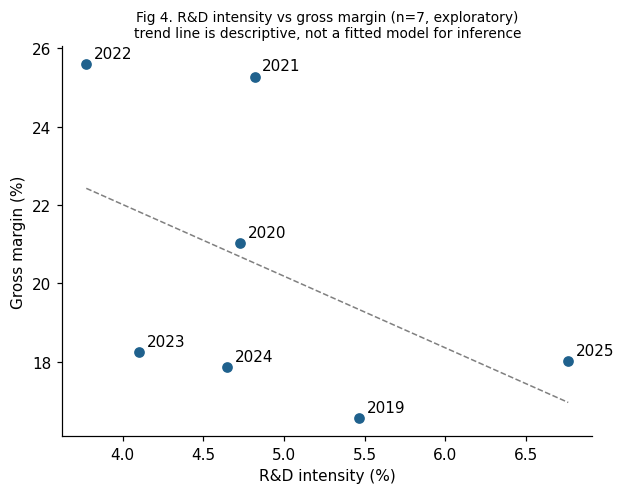

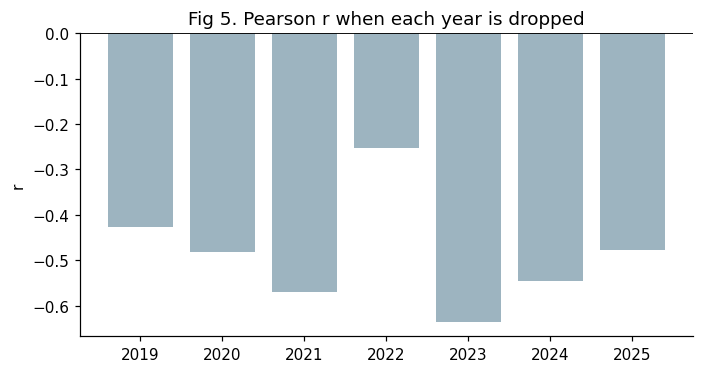

In [ ]:
fig,ax=plt.subplots(figsize=(5.8,4.6)); ax.scatter(d.rd_intensity_pct,d.gross_margin_pct,color='#1f618d')
for _,r_ in d.iterrows(): ax.annotate(int(r_.fiscal_year),(r_.rd_intensity_pct,r_.gross_margin_pct),xytext=(5,4),textcoords='offset points')
b=np.polyfit(d.rd_intensity_pct,d.gross_margin_pct,1); xs=np.linspace(d.rd_intensity_pct.min(),d.rd_intensity_pct.max(),50)
ax.plot(xs,np.polyval(b,xs),'--',color='grey',lw=1); ax.set_xlabel('R&D intensity (%)'); ax.set_ylabel('Gross margin (%)')
ax.set_title('Fig 4. R&D intensity vs gross margin (n=7, exploratory)\ntrend line is descriptive, not a fitted model for inference',fontsize=9); plt.tight_layout(); plt.savefig(OUT+'fig4_scatter.png'); plt.show()
fig,ax=plt.subplots(figsize=(6.5,3.5)); ax.bar(loo.year_dropped.astype(str),loo.pearson_r,color='#9db4c0'); ax.axhline(0,color='k',lw=.6)
ax.set_title('Fig 5. Pearson r when each year is dropped'); ax.set_ylabel('r'); plt.tight_layout(); plt.savefig(OUT+'fig5_loo.png'); plt.show()

## 6. Comparator data (RQ3) — *not* a like-for-like panel
Each row keeps its own currency, period and status. **No currency conversion and no cross-company USD ranking is performed.** BYD Electronic (HKEX 0285) is a listed subsidiary and is kept out of BYD Group figures.
Toyota: fiscal year ends 31 March (FY2026 = Apr 2025–Mar 2026), IFRS (since FY ended Mar 2021), no gross-profit headline → use operating margin. BYD: calendar year, CAS/IFRS dual reporting, diversified group (autos + handset components).

In [ ]:
TOY='https://global.toyota/en/ir/finance/'; TOYPDF='https://global.toyota/pages/global_toyota/ir/financial-results/2026_4q_presentation_2_en.pdf'
rows=[
('Toyota','Toyota Motor Corp (group)','FY2026 (Apr25–Mar26)','JPY bn','sales_revenue',50684.9,'S','Toyota FY2026 results presentation (PDF); also quoted in earnings briefing',TOYPDF,''),
('Toyota','Toyota Motor Corp (group)','FY2025 (Apr24–Mar25)','JPY bn','sales_revenue',48036.7,'S','Same presentation (prior-year column)',TOYPDF,''),
('Toyota','Toyota Motor Corp (group)','FY2026','%','operating_margin',7.4,'P','Toyota IR Financial Highlights page',TOY,'reported'),
('Toyota','Toyota Motor Corp (group)','FY2025','%','operating_margin',10.0,'P','Toyota IR Financial Highlights page',TOY,'reported'),
('Toyota','Toyota Motor Corp (group)','FY2024','%','operating_margin',11.9,'P','Toyota IR Financial Highlights page',TOY,'reported'),
('Toyota','Toyota Motor Corp (group)','FY2023','%','operating_margin',7.3,'P','Toyota IR Financial Highlights page',TOY,'reported'),
('Toyota','Toyota Motor Corp (group)','FY2026','JPY bn','rd_expense',1522.8,'S','Third-party summary (envalith.com) of Toyota results; confirm in Toyota Integrated Report/securities report','https://envalith.com/en/companies/7203/overview',''),
('Toyota','Toyota Motor Corp (group)','FY2025','JPY bn','rd_expense',1326.4,'S','Same third-party summary','https://envalith.com/en/companies/7203/overview',''),
('Toyota','Toyota Motor Corp (group)','FY2026','units (m)','consolidated_vehicle_sales',9.595,'S','Yahoo Finance report of earnings release','https://finance.yahoo.com/markets/stocks/articles/toyota-fy2026-earnings-miss-u-112836495.html','Toyota-reported figure is ~9.6m; unit definition differs from Tesla deliveries'),
('BYD','BYD Company Ltd (GROUP)','FY2025 (Jan–Dec)','RMB m','revenue',803965,'S','Press reports of audited 2025 results (confirm in HKEX annual report)','https://english.news18a.com/news/english_244599.html',''),
('BYD','BYD Company Ltd (GROUP)','FY2025','RMB m','gross_profit',142660,'S','Press report of audited results (rounded)','https://www-web.itiger.com/news/1158163115',''),
('BYD','BYD Company Ltd (GROUP)','FY2025','RMB m','rd_expense_income_statement',57978,'S','Press report (expensed R&D)','https://english.news18a.com/news/english_244599.html','Expensed R&D only'),
('BYD','BYD Company Ltd (GROUP)','FY2025','RMB m','rd_total_investment',63441,'S','Press report (includes capitalised R&D)','https://english.news18a.com/news/english_244599.html','NOT comparable to Tesla expensed R&D'),
('BYD','BYD Electronic (SUBSIDIARY, 0285)','FY2025','RMB m','revenue',179477,'P','HKEX results announcement (subsidiary only)','https://www1.hkexnews.hk/listedco/listconews/sehk/2026/0327/2026032702072.pdf','EXCLUDED from BYD Group comparison'),
]
comp=pd.DataFrame(rows,columns=['company','entity','period','unit','metric','value','verification','source_description','source_url','note'])
comp.to_csv(OUT+'comparator_data.csv',index=False); display(comp[['company','entity','period','unit','metric','value','verification','note']])

,company,entity,period,unit,metric,value,verification,note
0,Toyota,Toyota Motor Corp (group),FY2026 (Apr25–Mar26),JPY bn,sales_revenue,50684.900,S,
1,Toyota,Toyota Motor Corp (group),FY2025 (Apr24–Mar25),JPY bn,sales_revenue,48036.700,S,
2,Toyota,Toyota Motor Corp (group),FY2026,%,operating_margin,7.400,P,reported
3,Toyota,Toyota Motor Corp (group),FY2025,%,operating_margin,10.000,P,reported
4,Toyota,Toyota Motor Corp (group),FY2024,%,operating_margin,11.900,P,reported
5,Toyota,Toyota Motor Corp (group),FY2023,%,operating_margin,7.300,P,reported
6,Toyota,Toyota Motor Corp (group),FY2026,JPY bn,rd_expense,1522.800,S,
7,Toyota,Toyota Motor Corp (group),FY2025,JPY bn,rd_expense,1326.400,S,
8,Toyota,Toyota Motor Corp (group),FY2026,units (m),consolidated_vehicle_sales,9.595,S,Toyota-reported figure is ~9.6m; unit definition differs from Tesla deliveries
9,BYD,BYD Company Ltd (GROUP),FY2025 (Jan–Dec),RMB m,revenue,803965.000,S,


,company,period,metric,value_pct,status
0,Tesla,FY2025,Gross margin %,18.03,calculated (reported GP/revenue)
1,Tesla,FY2025,R&D (expensed) % revenue,6.76,calculated
2,BYD Group,FY2025,Gross margin %,17.74,calculated; press-report inputs (S)
3,BYD Group,FY2025,R&D expensed % revenue,7.21,calculated (S)
4,BYD Group,FY2025,Total R&D investment % revenue,7.89,calculated; includes capitalised R&D
5,Toyota,FY2026,Operating margin % (not gross margin),7.40,reported
6,Toyota,FY2026,R&D % revenue,3.00,calculated (S)


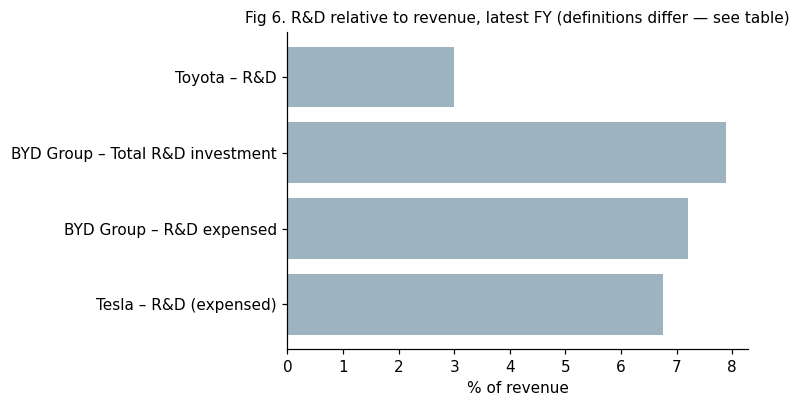

In [ ]:
# Within-company ratios only (each in its own currency); calculated
def g(c,p,m):
    s=comp[(comp.company==c)&(comp.period.str.startswith(p))&(comp.metric==m)&(~comp.entity.str.contains('SUBSIDIARY'))].value
    return s.iloc[0]
bench=pd.DataFrame([
 ['Tesla','FY2025','Gross margin %',d.gross_margin_pct.iloc[-1],'calculated (reported GP/revenue)'],
 ['Tesla','FY2025','R&D (expensed) % revenue',d.rd_intensity_pct.iloc[-1],'calculated'],
 ['BYD Group','FY2025','Gross margin %',g('BYD','FY2025','gross_profit')/g('BYD','FY2025','revenue')*100,'calculated; press-report inputs (S)'],
 ['BYD Group','FY2025','R&D expensed % revenue',g('BYD','FY2025','rd_expense_income_statement')/g('BYD','FY2025','revenue')*100,'calculated (S)'],
 ['BYD Group','FY2025','Total R&D investment % revenue',g('BYD','FY2025','rd_total_investment')/g('BYD','FY2025','revenue')*100,'calculated; includes capitalised R&D'],
 ['Toyota','FY2026','Operating margin % (not gross margin)',g('Toyota','FY2026','operating_margin'),'reported'],
 ['Toyota','FY2026','R&D % revenue',g('Toyota','FY2026','rd_expense')/g('Toyota','FY2026','sales_revenue')*100,'calculated (S)'],
],columns=['company','period','metric','value_pct','status']).round(2)
bench.to_csv(OUT+'benchmark_ratios.csv',index=False); display(bench)
fig,ax=plt.subplots(figsize=(7,3.8)); b=bench[bench.metric.str.contains('R&D')]
ax.barh(b.company+' – '+b.metric.str.replace(' % revenue',''),b.value_pct,color='#9db4c0'); ax.set_xlabel('% of revenue')
ax.set_title('Fig 6. R&D relative to revenue, latest FY (definitions differ — see table)',fontsize=10); plt.tight_layout(); plt.savefig(OUT+'fig6_rd_benchmark.png'); plt.show()

## 7. Source register

In [ ]:
src=pd.DataFrame([
('S1','Tesla','Form 10-K FY2025 (filed 2026-01-29) – primary','https://www.sec.gov/Archives/edgar/data/1318605/000162828026003952/tsla-20251231.htm','Revenue, credits, FY2024/2023 comparatives'),
('S2','Tesla','SEC EDGAR 10-K filing list (all years) – primary','https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=0001318605&type=10-K&dateb=&owner=include&count=40','FY2019–FY2024 10-Ks; open each Item 8 / Item 7 to cite page numbers'),
('S3','Tesla','SEC XBRL companyfacts API – primary data feed','https://data.sec.gov/api/xbrl/companyfacts/CIK0001318605.json','Automated check in §2'),
('S4','Tesla','edgar.tools TSLA summary – secondary','https://app.edgar.tools/companies/TSLA','Cross-check 2021–2025 revenue/GP/R&D'),
('S5','Tesla','sec-api.io FY2025 analysis – secondary','https://sec-api.io/insights/financial-analysis-of-tesla-fy2025-and-the-first-half-of-2026','Cross-check credits 2021–2025'),
('S6','Toyota','Toyota IR Financial Highlights – primary','https://global.toyota/en/ir/finance/','Operating margins FY2022–FY2026'),
('S7','Toyota','FY2026 Q4 results presentation – primary','https://global.toyota/pages/global_toyota/ir/financial-results/2026_4q_presentation_2_en.pdf','Revenue FY2026/FY2025, operating income'),
('S8','Toyota','envalith.com company overview – secondary','https://envalith.com/en/companies/7203/overview','R&D FY2025–26 (confirm in primary)'),
('S9','BYD','BYD Electronic HKEX results – primary (SUBSIDIARY)','https://www1.hkexnews.hk/listedco/listconews/sehk/2026/0327/2026032702072.pdf','Used only to document the subsidiary/parent distinction'),
('S10','BYD','News18a summary of 2025 results – secondary','https://english.news18a.com/news/english_244599.html','BYD Group FY2025 revenue, R&D, margin (confirm in HKEX annual report, stock code 01211)'),
('S11','BYD','iTiger report on 2025 results – secondary','https://www-web.itiger.com/news/1158163115','Gross profit FY2025'),
],columns=['id','company','description','url','used_for']); src.to_csv(OUT+'source_register.csv',index=False); display(src)

,id,company,description,url,used_for
0,S1,Tesla,Form 10-K FY2025 (filed 2026-01-29) – primary,https://www.sec.gov/Archives/edgar/data/1318605/000162828026003952/tsla-20251231.htm,"Revenue, credits, FY2024/2023 comparatives"
1,S2,Tesla,SEC EDGAR 10-K filing list (all years) – primary,https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=0001318605&type=10-K&da...,FY2019–FY2024 10-Ks; open each Item 8 / Item 7 to cite page numbers
2,S3,Tesla,SEC XBRL companyfacts API – primary data feed,https://data.sec.gov/api/xbrl/companyfacts/CIK0001318605.json,Automated check in §2
3,S4,Tesla,edgar.tools TSLA summary – secondary,https://app.edgar.tools/companies/TSLA,Cross-check 2021–2025 revenue/GP/R&D
4,S5,Tesla,sec-api.io FY2025 analysis – secondary,https://sec-api.io/insights/financial-analysis-of-tesla-fy2025-and-the-first-half-of-2026,Cross-check credits 2021–2025
5,S6,Toyota,Toyota IR Financial Highlights – primary,https://global.toyota/en/ir/finance/,Operating margins FY2022–FY2026
6,S7,Toyota,FY2026 Q4 results presentation – primary,https://global.toyota/pages/global_toyota/ir/financial-results/2026_4q_presentation_2_...,"Revenue FY2026/FY2025, operating income"
7,S8,Toyota,envalith.com company overview – secondary,https://envalith.com/en/companies/7203/overview,R&D FY2025–26 (confirm in primary)
8,S9,BYD,BYD Electronic HKEX results – primary (SUBSIDIARY),https://www1.hkexnews.hk/listedco/listconews/sehk/2026/0327/2026032702072.pdf,Used only to document the subsidiary/parent distinction
9,S10,BYD,News18a summary of 2025 results – secondary,https://english.news18a.com/news/english_244599.html,"BYD Group FY2025 revenue, R&D, margin (confirm in HKEX annual report, stock code 01211)"


## 8. Audit of the NotebookLM material (findings carried forward)

In [ ]:
audit=pd.DataFrame([
('Tesla 2019–2025 revenue/R&D/GP/credits','Numbers agree with filings/extractions (2021–25 cross-checked; 2019–20 check via §2)','OK (re-verify 19–20)'),
('Python snippet (Task 6)','Dictionary values were blank (`\'fiscal_year\': ,`) → SyntaxError','Fixed here'),
('Credit-adjusted margin = (GP − credits)/Revenue','Mixes bases; credits removed from numerator only. Correct sensitivity removes from both','Corrected (§3)'),
('"Actual performance: 54% range, 56% cost reduction" (4680)','These are Tesla 2020 Battery Day *targets*, not realised results','Mislabelled – exclude'),
('Shanghai cost cut >20%; battery lines 7× faster; ZEV credits $1.3B+','No primary source in the text','Unsupported – exclude until sourced'),
('"4 million connected fleet vehicles"; fleet-data moat','No source/date; fleet-size claims need Tesla disclosure','Unsupported'),
('Toyota R&D FY23 ¥1,241.6B / FY24 ¥1,202.3B; units FY23 8,821,872','Not verified; FY25–26 R&D differ in trend','Flagged – verify in Toyota reports'),
('Toyota ~70% ICE / ~28% HEV; HEV battery cost 1/6','No source','Unsupported'),
('Mixed BYD Group and BYD Electronic (RMB 177.3B, R&D RMB 4.9B)','Subsidiary ≠ group; placed in group column','Incomparable – removed'),
('BYD charging "secondary reliance on public grid"','Unsupported/likely outdated (BYD has promoted ultra-fast charging)','Verify before use'),
('Tesla "pure-play EV"','Energy storage is a second reportable segment ($12.8B revenue 2025)','Incomplete'),
('Tesla–BYD–Toyota table mixes FY (Apr–Mar) and calendar years, JPY/RMB/USD, GP margin vs operating margin','Not directly comparable','Handled in §6'),
('Gross-margin trend "25.6% → 18.2% → 18.0%"','Skips 2024 (17.9%); selective endpoints','Replaced by full series'),
('VRIO: software/EEA rated Yes on Inimitable','Over-asserted; no evidence legacy OEMs cannot replicate (e.g., BYD, Toyota software programmes)','Downgraded in §9'),
('Page references (e.g., p.50, p.49)','Not verified','Do not cite pages until checked'),
],columns=['claim','issue','status']); audit.to_csv(OUT+'audit_findings.csv',index=False); display(audit)

,claim,issue,status
0,Tesla 2019–2025 revenue/R&D/GP/credits,Numbers agree with filings/extractions (2021–25 cross-checked; 2019–20 check via §2),OK (re-verify 19–20)
1,Python snippet (Task 6),"Dictionary values were blank (`'fiscal_year': ,`) → SyntaxError",Fixed here
2,Credit-adjusted margin = (GP − credits)/Revenue,Mixes bases; credits removed from numerator only. Correct sensitivity removes from both,Corrected (§3)
3,"""Actual performance: 54% range, 56% cost reduction"" (4680)","These are Tesla 2020 Battery Day *targets*, not realised results",Mislabelled – exclude
4,Shanghai cost cut >20%; battery lines 7× faster; ZEV credits $1.3B+,No primary source in the text,Unsupported – exclude until sourced
5,"""4 million connected fleet vehicles""; fleet-data moat",No source/date; fleet-size claims need Tesla disclosure,Unsupported
6,"Toyota R&D FY23 ¥1,241.6B / FY24 ¥1,202.3B; units FY23 8,821,872",Not verified; FY25–26 R&D differ in trend,Flagged – verify in Toyota reports
7,Toyota ~70% ICE / ~28% HEV; HEV battery cost 1/6,No source,Unsupported
8,"Mixed BYD Group and BYD Electronic (RMB 177.3B, R&D RMB 4.9B)",Subsidiary ≠ group; placed in group column,Incomparable – removed
9,"BYD charging ""secondary reliance on public grid""",Unsupported/likely outdated (BYD has promoted ultra-fast charging),Verify before use


## 9. Strategic frameworks (RQ2, RQ5) — qualitative *judgements*; evidence column must be completed from sources in stage 2

In [ ]:
tech=pd.DataFrame([
('Software / OTA','Centralised EEA, OTA updates','Feature iteration, FSD subscriptions','Tesla 10-K (revenue disclosure, risk factors)','Need: software/services revenue split','Partially evidenced'),
('Battery (4680, BMS)','In-house cells; pack integration','Cost/energy density (targets, not results)','Tesla Battery Day 2020; 10-K','Need: production ramp & cost evidence','Targets only'),
('Manufacturing (Giga Casting, Gigafactories)','Fewer parts, faster build','Capex/unit, margin','10-K Item 1/7; peer-reviewed studies','Need: sourced cost figures; Toyota adoption','Partially evidenced'),
('Charging (Supercharger/NACS)','Proprietary DC network','Ecosystem lock-in → utility','Tesla IR; SAE J3400 / OEM announcements','Need: station counts with dates','Partially evidenced'),
('Energy storage','Megapack/Powerwall','Diversification, 2025 segment GM ~29.8% (secondary)','10-K segment note','Verify in 10-K','Evidenced (10-K)'),
],columns=['pillar','capability','advantage_mechanism','candidate_primary_source','gap','evidence_status'])
vrio=pd.DataFrame([
('Integrated software/EEA','Y','Partial','Partial','Y','Temporary–sustained (judgement)'),
('Supercharger network / NACS','Y','Partial','Partial','Y','Temporary (rivals adopting NACS)'),
('Manufacturing process (Giga Casting)','Y','N','N','Y','Parity/temporary'),
('Fleet data for AI','Y','Partial','Partial','Y','Contested – needs evidence'),
('4680 cells','Y','Partial','Y','Partial','Not yet realised'),
],columns=['resource','V','R','I','O','implication_judgement'])
swot=pd.DataFrame({'Strengths':['Brand/scale; energy segment growth; integration','',''],'Weaknesses':['Margin compression 2022→2025','Revenue decline 2025 (−2.9%)','R&D intensity up to 6.8% w/o margin recovery'],
 'Opportunities':['Energy storage','Software/autonomy (unproven)','Charging network monetisation'],'Threats':['BYD/Chinese price competition','Credit revenue decline (OBBBA)','Regulatory scrutiny of driver-assist']})
five=pd.DataFrame([('Rivalry','High'),('Buyer power','High'),('Supplier power','Moderate–High'),('New entrants','Moderate'),('Substitutes','Moderate (hybrids/ICE)')],columns=['force','rating_judgement'])
for n,t in [('tech_map',tech),('vrio',vrio),('swot',swot),('porter',five)]: t.to_csv(OUT+n+'.csv',index=False); print('\n##',n); display(t)


## tech_map


,pillar,capability,advantage_mechanism,candidate_primary_source,gap,evidence_status
0,Software / OTA,"Centralised EEA, OTA updates","Feature iteration, FSD subscriptions","Tesla 10-K (revenue disclosure, risk factors)",Need: software/services revenue split,Partially evidenced
1,"Battery (4680, BMS)",In-house cells; pack integration,"Cost/energy density (targets, not results)",Tesla Battery Day 2020; 10-K,Need: production ramp & cost evidence,Targets only
2,"Manufacturing (Giga Casting, Gigafactories)","Fewer parts, faster build","Capex/unit, margin",10-K Item 1/7; peer-reviewed studies,Need: sourced cost figures; Toyota adoption,Partially evidenced
3,Charging (Supercharger/NACS),Proprietary DC network,Ecosystem lock-in → utility,Tesla IR; SAE J3400 / OEM announcements,Need: station counts with dates,Partially evidenced
4,Energy storage,Megapack/Powerwall,"Diversification, 2025 segment GM ~29.8% (secondary)",10-K segment note,Verify in 10-K,Evidenced (10-K)



## vrio


,resource,V,R,I,O,implication_judgement
0,Integrated software/EEA,Y,Partial,Partial,Y,Temporary–sustained (judgement)
1,Supercharger network / NACS,Y,Partial,Partial,Y,Temporary (rivals adopting NACS)
2,Manufacturing process (Giga Casting),Y,N,N,Y,Parity/temporary
3,Fleet data for AI,Y,Partial,Partial,Y,Contested – needs evidence
4,4680 cells,Y,Partial,Y,Partial,Not yet realised



## swot


,Strengths,Weaknesses,Opportunities,Threats
0,Brand/scale; energy segment growth; integration,Margin compression 2022→2025,Energy storage,BYD/Chinese price competition
1,,Revenue decline 2025 (−2.9%),Software/autonomy (unproven),Credit revenue decline (OBBBA)
2,,R&D intensity up to 6.8% w/o margin recovery,Charging network monetisation,Regulatory scrutiny of driver-assist



## porter


,force,rating_judgement
0,Rivalry,High
1,Buyer power,High
2,Supplier power,Moderate–High
3,New entrants,Moderate
4,Substitutes,Moderate (hybrids/ICE)


## 10. Interpretation guide for the report (RQ5)
Draft recommendations must follow from §3–§9 evidence: e.g., (1) report margin with and without credits; (2) treat R&D–margin pattern as descriptive; (3) emphasise that Tesla’s 2025 R&D step-up coincided with flat margins, so payoffs (AI/autonomy, 4680) are not yet visible in reported financials; (4) benchmark against BYD on expensed-R&D basis only; (5) treat Toyota via operating margin. Strategy ratings are **judgements**; cite evidence for each.

In [ ]:
with zipfile.ZipFile('/content/tesla_study_outputs.zip','w') as z:
    for f in os.listdir(OUT): z.write(OUT+f,f)
try:
    from google.colab import files; files.download('/content/tesla_study_outputs.zip')
except Exception: print('Outputs in /content/outputs and tesla_study_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>